In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import mne
from mne.datasets.sleep_physionet.age import fetch_data

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

In [46]:
data = fetch_data(subjects=[0,1], recording=[1])

Using default location ~/mne_data for PHYSIONET_SLEEP...


In [47]:
data

[['/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4001E0-PSG.edf',
  '/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4001EC-Hypnogram.edf'],
 ['/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4011E0-PSG.edf',
  '/Users/sonakshisharma/mne_data/physionet-sleep-data/SC4011EH-Hypnogram.edf']]

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/2157174266.py:7: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/2157174266.py:9: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  raw_train.plot(start=60, duration=60, scalings=dict(eeg=1e-4, resp=1e3, eog=1e-4, emg=1e-7, misc=1e-1),)


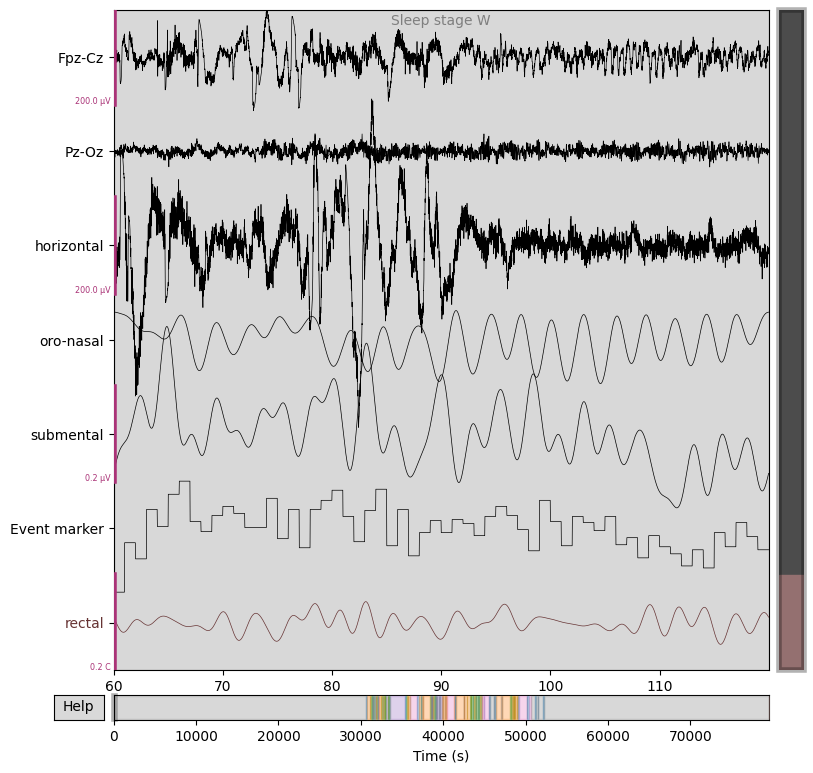

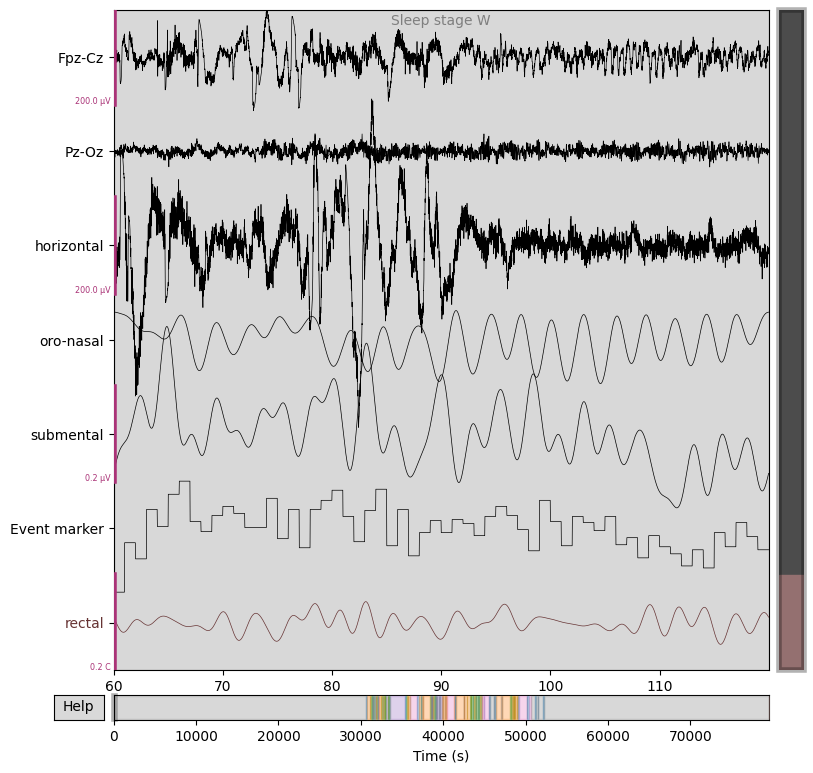

In [ ]:
raw_train = mne.io.read_raw_edf(data[0][0], stim_channel="Event Marker", infer_types=True, verbose="error",)

annot_train = mne.read_annotations(data[0][1])

raw_train.set_annotations(annot_train)

raw_train.plot(start=60, duration=60, scalings=dict(eeg=1e-4, resp=1e3, eog=1e-4, emg=1e-7, misc=1e-1),)

/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/20505406.py:12: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_train.set_annotations(annot_train)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']


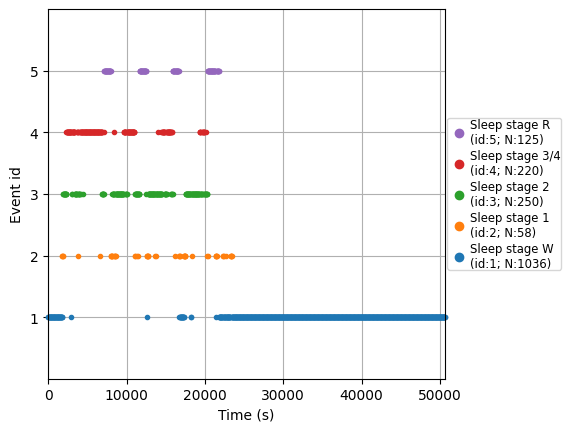

In [49]:
annotation_desc_2_event_id = { 
    "Sleep stage W": 1,
    "Sleep stage 1": 2,
    "Sleep stage 2": 3,
    "Sleep stage 3": 4,
    "Sleep stage 4": 4,
    "Sleep stage R": 5,
}

annot_train.crop(annot_train[1]["onset"] -30*60, annot_train[-1]["onset"] + 30*60)

raw_train.set_annotations(annot_train)

events_train, _ = mne.events_from_annotations(raw_train, event_id=annotation_desc_2_event_id, chunk_duration=30.0)

event_id = {
    "Sleep stage W": 1,
    "Sleep stage 1": 2,
    "Sleep stage 2": 3,
    "Sleep stage 3/4": 4,
    "Sleep stage R": 5,
}

fig = mne.viz.plot_events(
    events_train,
    event_id=event_id,
    sfreq=raw_train.info["sfreq"],
    first_samp=events_train[0,0],
)

stage_Colours=plt.rcParams["axes.prop_cycle"].by_key()["color"]

In [50]:
tmax =30.0 -1.0 /raw_train.info["sfreq"]
epochs_train=mne.Epochs(
    raw=raw_train,
    events=events_train,
    event_id=event_id,
    tmin=0.0,
    tmax=tmax,
    baseline=None,
)

del raw_train

print(epochs_train)

Not setting metadata
1689 matching events found
No baseline correction applied
0 projection items activated
<Epochs | 1689 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1036
 'Sleep stage 1': 58
 'Sleep stage 2': 250
 'Sleep stage 3/4': 220
 'Sleep stage R': 125>


In [51]:
raw_test = mne.io.read_raw_edf(
    data[1][0], stim_channel="Event Marker", infer_types=True, verbose="error"
)

annot_test = mne.read_annotations(data[1][1])

annot_test.crop(annot_test[1]["onset"] -30*60, annot_test[-1]["onset"] + 30*60)

raw_test.set_annotations(annot_test)

events_test, _ = mne.events_from_annotations(raw_test, event_id=annotation_desc_2_event_id, chunk_duration=30.0)

epochs_test=mne.Epochs(
    raw=raw_test,
    events=events_test,
    event_id=event_id,
    tmin=0.0,
    tmax=tmax,
    baseline=None,
)

del raw_test 

print(epochs_test)


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/3607067979.py:9: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_test.set_annotations(annot_test)


Used Annotations descriptions: ['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage R', 'Sleep stage W']
Not setting metadata
2144 matching events found
No baseline correction applied
0 projection items activated
<Epochs | 2144 events (good & bad), 0 – 29.99 s (baseline off), ~10 KiB, data not loaded,
 'Sleep stage W': 1198
 'Sleep stage 1': 109
 'Sleep stage 2': 562
 'Sleep stage 3/4': 105
 'Sleep stage R': 170>


### Feature Engineering

Loading data for 58 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1,fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1,fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635


0 bad epochs dropped
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Loading data for 250 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1,fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1,fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635


0 bad epochs dropped
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Loading data for 220 events and 3000 original time points ...


...

Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Loading data for 1198 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1,fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1,fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635


0 bad epochs dropped
    Using multitaper spectrum estimation with 7 DPSS windows


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1,fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs[stage].compute_psd(fmin=0.1,fmax=20.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/1217656123.py:7: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635


Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


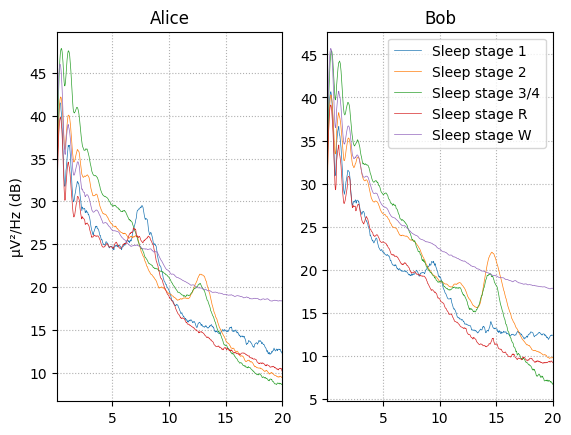

In [52]:
fig, (ax1,ax2) = plt.subplots(ncols=2)

stages = sorted(event_id.keys())

for ax,title,epochs in zip([ax1,ax2], ["Alice","Bob"], [epochs_train,epochs_test]):
    for stage,colour in zip(stages,stage_Colours):
        spectrum = epochs[stage].compute_psd(fmin=0.1,fmax=20.0)
        spectrum.plot(
            ci=None,
            color=colour,
            axes = ax,
            show=False,
            average=True,
            amplitude=False,
            spatial_colors=False,
            picks="data",
            exclude="bads",
        )
    ax.set_title(title)
ax1.set(ylabel="µV²/Hz (dB)")
ax2.legend(ax2.lines[2::3], stages)
plt.show()

In [60]:
def eeg_power_band(epochs):
    FREQ_BANDS = {
        "delta":[0.5,4.5],
        "theta": [4.5,8.5],
        "alpha": [8.5, 11.5],
        "sigma": [11.5, 15.5],
        "beta": [15.5, 30.0],
    }   

    spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)

    psds,freqs = spectrum.get_data(return_freqs=True)

    psds/= np.sum(psds,axis=-1,keepdims=True)

    X= []
    for fmin,fmax in FREQ_BANDS.values():
        psds_band = psds[:,:,(freqs>=fmin)& (freqs<fmax)].mean(axis=-1)
        X.append(psds_band.reshape(len(psds),-1))

    return np.concatenate(X,axis=-1)

In [61]:
pipeline = make_pipeline(
    FunctionTransformer(eeg_power_band, validate=False),
    RandomForestClassifier(n_estimators=100, random_state=42),
)

y_train = epochs_train.events[:,2]

pipeline.fit(epochs_train,y_train)

y_pred = pipeline.predict(epochs_test)

y_test = epochs_test.events[:,2]

acc = accuracy_score(y_test,y_pred)

print(f"Test accuracy: {acc}")

Loading data for 1689 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/i

    Using multitaper spectrum estimation with 7 DPSS windows


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/i

Loading data for 2144 events and 3000 original time points ...


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/i

0 bad epochs dropped


/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  spectrum = epochs.compute_psd(picks="eeg", fmin=0.5,fmax=30.0)
/var/folders/9n/d1ggjg713yq6lrkgcz8bss640000gn/T/ipykernel_98071/781982914.py:10: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/i

    Using multitaper spectrum estimation with 7 DPSS windows
Test accuracy: 0.8185634328358209


In [62]:
print(confusion_matrix(y_test, y_pred))

[[1196    0    0    2    0]
 [  94    8    2    1    4]
 [  91   12  420   26   13]
 [   0    0    3  102    0]
 [  79   46   16    0   29]]


In [63]:
print(classification_report(y_test, y_pred, target_names=event_id.keys()))

                 precision    recall  f1-score   support

  Sleep stage W       0.82      1.00      0.90      1198
  Sleep stage 1       0.12      0.07      0.09       109
  Sleep stage 2       0.95      0.75      0.84       562
Sleep stage 3/4       0.78      0.97      0.86       105
  Sleep stage R       0.63      0.17      0.27       170

       accuracy                           0.82      2144
      macro avg       0.66      0.59      0.59      2144
   weighted avg       0.80      0.82      0.79      2144

